# Adaptive Behavioural Prototype Graph Clustering (Adaptive BPGC)
### Dubai Metro Station Profiling

The model groups standardized station-window ridership profiles. Its spatial penalty is stronger between adjacent stations with similar ridership relative to their local feature-space neighbourhoods. The graph links stations within each observation window.

\[
J(z,\mu)=\sum_i \|x_i-\mu_{z_i}\|^2+
\lambda\,s\sum_{(i,j)\in E_s}\widetilde{w}_{ij}\,\mathbf 1[z_i\ne z_j].
\]

For each observation, \(\sigma_i\) is the distance to its seventh nearest other observation in feature space. The adaptive edge weight is proportional to \(w_{ij}\exp(-\|x_i-x_j\|^2/(\sigma_i\sigma_j))\). Rescaling preserves the total weight of the input spatial graph. The penalty scale \(s\) is the mean squared distance from a reference K-Means fit, shared across restarts of each model fit. We use six clusters for the main comparison and examine other cluster counts in the sensitivity sweep.

The edge weighting adapts the local scaling proposed by Zelnik-Manor and Perona to BPGC's existing spatial edges. [Self-Tuning Spectral Clustering](https://proceedings.neurips.cc/paper/2004/hash/40173ea48d9567f1f393b20c855bb40b-Abstract.html)

## 1. Configuration

In [1]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

SEED = 42
K = 6
LOCAL_NEIGHBORS = 7
ADAPTIVE_METHOD = "Adaptive BPGC"
DBSCAN_MIN_SAMPLES = 5
DBSCAN_EPS_PERCENTILE = 90
RESTARTS = 20                 # Main-fit restart budget for Adaptive BPGC and K-Means
KMEANS_INIT = RESTARTS
STAB_INIT = 10                # Restart budget per stability refit for both prototype methods
MAX_ITER = 60
INNER_SWEEPS = 12
LAMBDA_GRID = [0.0, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 4.0]
SIL_TOL = 0.04                # lambda rule: allow silhouette to drop at most this far below its best value
STABILITY_REPEATS = 20
K_RANGE = range(2, 11)
REDUCE_COLLINEAR = False      # True drops check_in/out_share_20_24 (each share group sums to 1)
USE_S3 = False
ROOT = Path.cwd().resolve()
if not (ROOT / "reference").exists() and (ROOT.parent / "reference").exists():
    ROOT = ROOT.parent
FEATURES_FILE = ROOT / "results/features/features.parquet"
EDGES_FILE = ROOT / "reference/edges.csv"
OUTPUT_DIR = ROOT / "results/bpgc"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)
print("Local features:", FEATURES_FILE.exists(), "| Spatial graph:", EDGES_FILE.exists())

Project root: /Users/aryanchandra/Downloads/Metro-Spectral-STGRSC
Local features: True | Spatial graph: True


## 2. Load and validate the feature table

In [2]:
def canonical_id(v):
    num = pd.to_numeric(pd.Series([v]), errors="coerce").iloc[0]
    return str(int(num)) if pd.notna(num) and float(num).is_integer() else str(v).strip()

if USE_S3:
    import boto3
    import awswrangler as wr
    session = boto3.Session(
        profile_name=os.environ.get("AWS_PROFILE") or None,
        region_name=os.environ.get("AWS_DEFAULT_REGION", "ap-south-1")
    )
    bucket = os.environ.get("METRO_S3_BUCKET")
    if not bucket:
        account = session.client("sts").get_caller_identity()["Account"]
        bucket = f"dubai-metro-profiling-{account}"
    df = wr.s3.read_parquet(f"s3://{bucket}/curated/features/", boto3_session=session)
else:
    if not FEATURES_FILE.exists():
        raise FileNotFoundError(f"Missing {FEATURES_FILE}. Set USE_S3=True for your existing AWS source.")
    df = pd.read_parquet(FEATURES_FILE)

KEY_COLUMNS = ["win", "location_id", "station"]
AUX_COLUMNS = ["timed_taps", "check_ins", "check_outs"]
required = KEY_COLUMNS + AUX_COLUMNS
if not set(required).issubset(df.columns):
    raise ValueError(f"Missing columns: {sorted(set(required)-set(df.columns))}")
if df.duplicated(["win", "location_id"]).any():
    raise ValueError("Duplicate station-window keys")
df = df.sort_values(["win", "location_id"], kind="stable").reset_index(drop=True)
feature_cols = [c for c in df.columns if c not in KEY_COLUMNS + AUX_COLUMNS]
if not all(pd.api.types.is_numeric_dtype(df[c]) for c in feature_cols):
    raise ValueError("Non-numeric feature columns")
if REDUCE_COLLINEAR:
    feature_cols = [c for c in feature_cols if c not in ("check_in_share_20_24", "check_out_share_20_24")]
X = df[feature_cols].to_numpy(dtype=float)
if not np.isfinite(X).all():
    raise ValueError("Non-finite feature values")
expected_shape = (244, 15 if REDUCE_COLLINEAR else 17)
if X.shape != expected_shape:
    raise ValueError(f"Expected {expected_shape}, received {X.shape}")
df["station_key"] = df["location_id"].map(canonical_id)
node_to_idx = {(str(row.win), row.station_key): i for i, row in enumerate(df.itertuples())}
if len(node_to_idx) != len(df):
    raise ValueError("Non-unique graph node identifiers")
print("Feature matrix:", X.shape, "| physical stations:", df.station_key.nunique())
display(df[KEY_COLUMNS + feature_cols[:3]].head())

Feature matrix: (244, 17) | physical stations: 53


,win,location_id,station,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16
0,W17/18,128,centrepoint,1.458880,1.107092,-0.005825
1,W17/18,129,Emirates,-0.806555,-0.988479,1.188134
2,W17/18,130,Airport Terminal 3,1.679147,0.411498,1.614566
3,W17/18,131,Airport Terminal 1,0.640393,-0.493969,1.222873
4,W17/18,132,GGICO,-1.571480,-1.012579,0.424582


## 3. Spatial graph and adaptive weights

Keep the original spatial edge weights for evaluation. Adaptive BPGC fits with weights estimated from the ridership features available in each fit.

In [3]:
if not EDGES_FILE.exists():
    raise FileNotFoundError(f"Missing {EDGES_FILE}; copy the existing station graph reference file.")
edges = pd.read_csv(EDGES_FILE, dtype={
    "src_win":str, "src_location_id":str,
    "dst_win":str, "dst_location_id":str, "kind":str
})
needed = {"src_win","src_location_id","dst_win","dst_location_id","kind","weight"}
if not needed.issubset(edges.columns):
    raise ValueError(f"Missing edge columns: {sorted(needed-set(edges.columns))}")
spatial = edges.loc[edges["kind"].eq("spatial")].copy()
if spatial.empty:
    raise ValueError("No spatial edges")
pairs, weights, seen = [], [], set()
for e in spatial.itertuples(index=False):
    a = (str(e.src_win), canonical_id(e.src_location_id))
    b = (str(e.dst_win), canonical_id(e.dst_location_id))
    if a not in node_to_idx or b not in node_to_idx:
        raise ValueError(f"Unmatched spatial edge: {a} -> {b}")
    i, j = node_to_idx[a], node_to_idx[b]
    if i == j:
        continue
    key = tuple(sorted((i,j)))
    if key in seen:
        raise ValueError(f"Duplicate spatial edge {key}")
    seen.add(key)
    weight = float(e.weight)
    if not np.isfinite(weight) or weight <= 0:
        raise ValueError("Invalid spatial edge weight")
    pairs.append(key)
    weights.append(weight)
pairs = np.asarray(pairs, dtype=int).reshape(-1,2)
weights = np.asarray(weights, dtype=float)
if not len(weights):
    raise ValueError("No spatial edges between distinct observations")
weights /= weights.mean()


def adaptive_edge_weights(x, pair_ix, base_weights, n_neighbors):
    if not len(pair_ix):
        return base_weights.copy()

    rank = min(n_neighbors, len(x) - 1)
    neighbors = NearestNeighbors(n_neighbors=rank).fit(x)
    distances = neighbors.kneighbors(return_distance=True)[0]
    scales = np.maximum(distances[:, -1], np.finfo(float).eps)

    left, right = pair_ix.T
    squared_distances = np.square(x[left] - x[right]).sum(axis=1)
    log_weights = np.log(base_weights) - squared_distances / (scales[left] * scales[right])
    # Subtract a common offset before exponentiating to preserve the relative weights.
    adjusted = np.exp(log_weights - log_weights.max())
    return adjusted * (base_weights.sum() / adjusted.sum())


adaptive_weights = adaptive_edge_weights(X, pairs, weights, LOCAL_NEIGHBORS)

def connectivity(pair_ix, n):
    r = np.r_[pair_ix[:,0], pair_ix[:,1]]
    c = np.r_[pair_ix[:,1], pair_ix[:,0]]
    return csr_matrix((np.ones(len(r)), (r, c)), shape=(n, n))

A = np.zeros((len(X),len(X)),dtype=float)
A[pairs[:,0],pairs[:,1]] = weights
A[pairs[:,1],pairs[:,0]] = weights
n_comp, _ = connected_components(connectivity(pairs, len(X)), directed=False)
print("Spatial edges:", len(pairs), "| temporal edges used: 0")
print("Isolated observations:", int((A.sum(axis=1)==0).sum()), "| connected components:", n_comp,
      "| mean degree:", round(2*len(pairs)/len(X), 2))
print("Adaptive weight quantiles (0%, 50%, 100%):", np.round(np.quantile(adaptive_weights, [0, 0.5, 1]), 4))

Spatial edges: 244 | temporal edges used: 0
Isolated observations: 0 | connected components: 5 | mean degree: 2.0
Adaptive weight quantiles (0%, 50%, 100%): [0.     0.2336 6.5604]


## 4. Adaptive BPGC algorithm

With the prototype centres fixed, each assignment update minimizes squared distance plus the adaptive weight of spatial edges that would cross clusters. Updating each prototype to the mean of its assigned observations then minimizes the feature term. Edge weights and the penalty scale stay fixed across restarts, so all restarts minimize the same objective. Setting λ to zero removes the spatial term.

In [4]:
def sqdist(x, centers):
    return cdist(x, centers, metric="sqeuclidean")

def energy(x, labels, centers, pair_ix, fit_weights, lam, scale):
    fit = float(sqdist(x, centers)[np.arange(len(x)), labels].sum())
    disagreement = float(fit_weights[labels[pair_ix[:, 0]] != labels[pair_ix[:, 1]]].sum())
    return fit + lam * scale * disagreement, fit, disagreement

def fit_adaptive_bpgc(x, pair_ix, fit_weights, k, lam, seed, restarts, max_iter, inner_sweeps):
    n = len(x)
    if n < k: raise ValueError("k larger than sample size")
    if lam < 0: raise ValueError("lambda must be nonnegative")

    nbr_idx = [[] for _ in range(n)]
    nbr_w = [[] for _ in range(n)]
    for (i, j), w in zip(pair_ix, fit_weights):
        nbr_idx[i].append(j); nbr_w[i].append(float(w))
        nbr_idx[j].append(i); nbr_w[j].append(float(w))
    nbr_idx = [np.asarray(v, dtype=int) for v in nbr_idx]
    nbr_w = [np.asarray(v, dtype=float) for v in nbr_w]
    strength = np.array([v.sum() for v in nbr_w])

    ref = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(x)
    scale = max(float(ref.inertia_) / n, 1e-10)

    best = None
    for restart in range(restarts):
        km = KMeans(n_clusters=k, n_init=1, random_state=seed + restart).fit(x)
        labels = km.labels_.copy()
        centers = km.cluster_centers_.copy()
        history = []
        for iteration in range(max_iter):
            old = labels.copy()
            D = sqdist(x, centers)                       # centres are fixed during sweeps
            for sweep in range(inner_sweeps):
                changed = 0
                order = np.random.default_rng(seed + restart*100003 + iteration*101 + sweep).permutation(n)
                for i in order:
                    cost = D[i].copy()
                    if lam > 0 and len(nbr_idx[i]):
                        same = np.bincount(labels[nbr_idx[i]], weights=nbr_w[i], minlength=k)
                        cost += lam * scale * (strength[i] - same)
                    choice = int(np.argmin(cost))
                    if choice != labels[i]:
                        labels[i] = choice
                        changed += 1
                if changed == 0: break
            counts = np.bincount(labels, minlength=k)
            if np.any(counts == 0):
                break                                    # reject restart with an empty prototype
            centers = np.vstack([x[labels == c].mean(axis=0) for c in range(k)])
            obj, fit, disagree = energy(x, labels, centers, pair_ix, fit_weights, lam, scale)
            history.append(obj)
            if np.array_equal(labels, old): break
        if np.any(np.bincount(labels, minlength=k) == 0): continue
        obj, fit, disagree = energy(x, labels, centers, pair_ix, fit_weights, lam, scale)
        if best is None or obj < best["objective"]:
            best = dict(labels=labels.copy(), centers=centers.copy(), objective=obj,
                        sse=fit, disagreement=disagree, history=history,
                        scale=scale, iterations=len(history), restart=restart)
    if best is None: raise RuntimeError("All Adaptive BPGC restarts ended with empty clusters")
    return best

def spatial_consistency(labels, pair_ix, pair_weights, adjust=False):
    # Weighted fraction of edges whose endpoints share a label.
    # adjust=True: kappa-style correction for the agreement expected from cluster sizes alone.
    if len(pair_ix) == 0: return np.nan
    agree = float(np.average(labels[pair_ix[:,0]] == labels[pair_ix[:,1]], weights=pair_weights))
    if not adjust: return agree
    ends = np.concatenate([labels[pair_ix[:,0]], labels[pair_ix[:,1]]])
    w = np.concatenate([pair_weights, pair_weights])
    q = pd.Series(w).groupby(ends).sum() / w.sum()
    expected = float((q ** 2).sum())
    return (agree - expected) / (1 - expected) if expected < 1 else np.nan

def evaluate(name, x, labels, pair_ix, pair_weights):
    labels = np.asarray(labels)
    assigned = labels != -1
    cluster_labels = labels[assigned]
    clustered_x = x[assigned]
    clusters, sizes = np.unique(cluster_labels, return_counts=True)
    k = len(clusters)
    valid_scores = 1 < k < len(cluster_labels)

    sse = 0.0
    for cluster in clusters:
        points = clustered_x[cluster_labels == cluster]
        sse += np.sum((points - points.mean(axis=0)) ** 2)

    assigned_edges = assigned[pair_ix].all(axis=1)
    edge_weights = pair_weights[assigned_edges]
    edge_coverage = edge_weights.sum() / pair_weights.sum() if len(pair_ix) else np.nan
    return dict(
        Method=name, N=len(x), Clusters=k,
        Noise_Points=int((~assigned).sum()), Coverage=float(assigned.mean()),
        Silhouette=float(silhouette_score(clustered_x, cluster_labels)) if valid_scores else np.nan,
        Davies_Bouldin=float(davies_bouldin_score(clustered_x, cluster_labels)) if valid_scores else np.nan,
        Calinski_Harabasz=float(calinski_harabasz_score(clustered_x, cluster_labels)) if valid_scores else np.nan,
        SSE=float(sse) if k else np.nan,
        Spatial_Consistency=spatial_consistency(labels, pair_ix[assigned_edges], edge_weights),
        Spatial_Consistency_Adj=spatial_consistency(labels, pair_ix[assigned_edges], edge_weights, adjust=True),
        Spatial_Edge_Coverage=float(edge_coverage),
        Smallest_Cluster=int(sizes.min()) if k else 0,
        Largest_Cluster=int(sizes.max()) if k else 0,
        Largest_Cluster_Share=float(sizes.max() / len(cluster_labels)) if k else np.nan,
    )

## 5. Adaptive BPGC penalty selection

Among λ values within the configured tolerance of the best silhouette, select the one with the highest chance-adjusted agreement on the original spatial edges. The reported objective uses the adaptive edge weights and is minimized separately at each λ. The same observations are used for tuning and evaluation, so these scores describe this dataset.

In [5]:
sweep_rows, fitted = [], {}
for lam in LAMBDA_GRID:
    fit = fit_adaptive_bpgc(
        X, pairs, adaptive_weights, k=K, lam=lam, seed=SEED,
        restarts=RESTARTS, max_iter=MAX_ITER, inner_sweeps=INNER_SWEEPS,
    )
    fitted[lam] = fit
    row = evaluate(f"{ADAPTIVE_METHOD} λ={lam:g}", X, fit["labels"], pairs, weights)
    row.update(Lambda=lam, Local_Neighbors=LOCAL_NEIGHBORS, Objective=fit["objective"],
               Adaptive_Disagreement=fit["disagreement"], Iterations=fit["iterations"])
    sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows)
display(sweep[["Lambda","Silhouette","Davies_Bouldin","Calinski_Harabasz","SSE",
               "Spatial_Consistency","Spatial_Consistency_Adj","Smallest_Cluster","Largest_Cluster",
               "Adaptive_Disagreement","Objective","Iterations"]].round(4))

max_sil_lambda = float(sweep.loc[sweep["Silhouette"].idxmax(), "Lambda"])
eligible = sweep[sweep["Silhouette"] >= sweep["Silhouette"].max() - SIL_TOL]
best_lambda = float(eligible.loc[eligible["Spatial_Consistency_Adj"].idxmax(), "Lambda"])
best_fit = fitted[best_lambda]
adaptive_labels = best_fit["labels"]
print("Max-silhouette λ (reference only):", max_sil_lambda)
print("Selected λ (rule above):", best_lambda)
print("Cluster counts:", np.bincount(adaptive_labels, minlength=K))

,Lambda,Silhouette,Davies_Bouldin,Calinski_Harabasz,SSE,Spatial_Consistency,Spatial_Consistency_Adj,Smallest_Cluster,Largest_Cluster,Adaptive_Disagreement,Objective,Iterations
0,0.00,0.2696,1.3129,90.8593,1426.0136,0.3893,0.2227,6,72,46.8636,1426.0136,1
1,0.05,0.2730,1.3120,90.8788,1425.8127,0.3934,0.2264,6,73,44.7081,1438.8772,4
2,0.10,0.2744,1.3113,90.7918,1426.7092,0.4016,0.2354,6,74,42.1424,1451.3386,4
3,0.25,0.2695,1.3135,89.6810,1438.2525,0.4221,0.2640,6,72,32.4419,1485.6527,3
4,0.50,0.2707,1.3135,88.5008,1450.7248,0.4467,0.2946,6,72,25.5933,1525.5126,4
5,0.75,0.2649,1.3128,87.0345,1466.5245,0.4672,0.3227,6,70,21.1047,1559.0315,3
6,1.00,0.2612,1.3268,85.5522,1482.8502,0.4795,0.3370,6,71,17.7408,1586.5330,3
7,1.50,0.2575,1.3313,83.4298,1506.8692,0.4918,0.3517,6,71,15.3609,1641.5305,3
8,2.00,0.2768,1.2823,78.6138,1564.3672,0.5205,0.3546,6,89,9.9449,1680.6091,4
9,4.00,0.2637,1.3236,74.8858,1611.9809,0.5410,0.3823,6,88,8.0694,1800.6205,2


Max-silhouette λ (reference only): 2.0
Selected λ (rule above): 4.0
Cluster counts: [43 88 59 37  6 11]


## 6. Baseline comparison

All methods use the same standardized matrix and are scored on the original spatial graph. K-Means and Adaptive BPGC use the same number of restarts. Spatial Ward uses the original graph as connectivity. DBSCAN uses the configured nearest-neighbour percentile for ε. Read its scores alongside coverage and largest-cluster share.

In [6]:
def fit_ward_spatial(x, pair_ix):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")   # sklearn completes a disconnected graph; fine for our use
        return AgglomerativeClustering(n_clusters=K, linkage="ward",
                                       connectivity=connectivity(pair_ix, len(x))).fit_predict(x)

kmeans_labels = KMeans(n_clusters=K, n_init=KMEANS_INIT, random_state=SEED).fit_predict(X)
ward_labels = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
ward_sp_labels = fit_ward_spatial(X, pairs)

neighbors = NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES).fit(X)
distances, _ = neighbors.kneighbors(X)
dbscan_params = {
    "eps": float(np.percentile(distances[:, -1], DBSCAN_EPS_PERCENTILE)),
    "min_samples": DBSCAN_MIN_SAMPLES,
}
dbscan_labels = DBSCAN(**dbscan_params).fit_predict(X)

adaptive_name = f"{ADAPTIVE_METHOD} (λ={best_lambda:g})"
method_labels = {
    "K-Means": kmeans_labels,
    "Ward": ward_labels,
    "Ward (spatial)": ward_sp_labels,
    adaptive_name: adaptive_labels,
    "DBSCAN": dbscan_labels,
}
comparison = pd.DataFrame([evaluate(m, X, l, pairs, weights) for m, l in method_labels.items()])
dbscan_row = comparison["Method"].eq("DBSCAN")
comparison.loc[dbscan_row, "Eps"] = dbscan_params["eps"]
comparison.loc[dbscan_row, "Min_Samples"] = dbscan_params["min_samples"]
adaptive_row = comparison["Method"].eq(adaptive_name)
comparison.loc[adaptive_row, "Lambda"] = best_lambda
comparison.loc[adaptive_row, "Local_Neighbors"] = LOCAL_NEIGHBORS
display(comparison.round(4))

,Method,N,Clusters,Noise_Points,Coverage,Silhouette,Davies_Bouldin,Calinski_Harabasz,SSE,Spatial_Consistency,Spatial_Consistency_Adj,Spatial_Edge_Coverage,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share,Eps,Min_Samples,Lambda,Local_Neighbors
0,K-Means,244,6,0,1.0000,0.2696,1.3129,90.8593,1426.0136,0.3893,0.2227,1.0000,6,72,0.2951,NaN,NaN,NaN,NaN
1,Ward,244,6,0,1.0000,0.2785,1.3151,81.7876,1525.9942,0.4795,0.3179,1.0000,6,83,0.3402,NaN,NaN,NaN,NaN
2,Ward (spatial),244,6,0,1.0000,0.0314,4.9856,10.5276,3396.7504,0.9549,0.9334,1.0000,8,116,0.4754,NaN,NaN,NaN,NaN
3,Adaptive BPGC (λ=4),244,6,0,1.0000,0.2637,1.3236,74.8858,1611.9809,0.5410,0.3823,1.0000,6,88,0.3607,NaN,NaN,4.0,7.0
4,DBSCAN,244,4,7,0.9713,-0.0124,1.2063,8.1086,3477.5383,0.8957,0.2543,0.9426,4,218,0.9198,2.6423,5.0,NaN,NaN


## 7. Graph partition quality

Normalized cut evaluates every method on the same affinity graph, with 98% of its total weight from feature similarity and 2% from the original spatial graph. DBSCAN noise counts as an additional partition. The reported ratio divides by the approximate unstructured reference of \(P-1\) for \(P\) partitions.

In [7]:
def normalized_cut(W, labels):
    labels = np.asarray(labels)
    deg = W.sum(axis=1)
    total = 0.0
    for c in np.unique(labels):
        m = labels == c
        vol = float(deg[m].sum())
        if vol <= 0: return np.nan
        total += float(W[np.ix_(m,~m)].sum())/vol
    return total

sigma = float(np.median(pdist(X)))
B = np.exp(-squareform(pdist(X,metric="sqeuclidean"))/(2*sigma*sigma))
np.fill_diagonal(B,0)
B /= B.sum()
G = A/A.sum()
W_eval = 0.98*B + 0.02*G

rows = []
for method, labels in method_labels.items():
    P = np.unique(labels).size
    nc = normalized_cut(W_eval, labels)
    rows.append({"Method": method, "Partitions": P, "Noise_Points": int((labels == -1).sum()),
                 "Ncut (same graph)": nc, "Ncut_ratio": nc / (P - 1) if P > 1 else np.nan})
ncut = pd.DataFrame(rows)
display(ncut.round(4))

,Method,Partitions,Noise_Points,Ncut (same graph),Ncut_ratio
0,K-Means,6,0,4.6204,0.9241
1,Ward,6,0,4.6315,0.9263
2,Ward (spatial),6,0,4.8347,0.9669
3,Adaptive BPGC (λ=4),6,0,4.6376,0.9275
4,DBSCAN,5,7,3.9515,0.9879


## 8. Station-grouped stability

The methods refit on the same 80% station subsamples and compare with their corresponding full-data assignments using adjusted Rand index (ARI). Adaptive BPGC recomputes local scales, adaptive weights and the penalty scale from the retained observations and induced spatial edges, using the selected λ and cluster count. Spatial Ward uses the induced graph. DBSCAN uses the full-fit ε and includes noise in ARI.

In [8]:
def cluster_with(method, x, pair_ix, pair_w, seed):
    if method == "K-Means":
        return KMeans(n_clusters=K, n_init=STAB_INIT, random_state=seed).fit_predict(x)
    if method == "Ward":
        return AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(x)
    if method == "Ward (spatial)":
        return fit_ward_spatial(x, pair_ix)
    if method == "DBSCAN":
        return DBSCAN(**dbscan_params).fit_predict(x)
    if method == ADAPTIVE_METHOD:
        sub_weights = adaptive_edge_weights(x, pair_ix, pair_w, LOCAL_NEIGHBORS)
        fit = fit_adaptive_bpgc(
            x, pair_ix, sub_weights, k=K, lam=best_lambda, seed=seed,
            restarts=STAB_INIT, max_iter=MAX_ITER, inner_sweeps=INNER_SWEEPS,
        )
        return fit["labels"]
    raise ValueError(method)

def stability_for(method, full_labels, repeats=20, frac=0.8):
    rng = np.random.default_rng(SEED + 2026)          # identical subsamples for every method
    station_ids = np.array(sorted(df.station_key.unique()))
    rows = []
    for rep in range(repeats):
        selected = rng.choice(station_ids, size=int(np.ceil(frac*len(station_ids))), replace=False)
        indices = np.flatnonzero(df.station_key.isin(selected).to_numpy())
        mapping = {old: i for i, old in enumerate(indices)}
        keep = np.isin(pairs[:,0], indices) & np.isin(pairs[:,1], indices)
        subpairs = np.array([[mapping[i], mapping[j]] for i, j in pairs[keep]], dtype=int).reshape(-1,2)
        sublabels = cluster_with(method, X[indices], subpairs, weights[keep], SEED + rep)
        rows.append(dict(Method=method, Replicate=rep+1,
                         ARI=float(adjusted_rand_score(full_labels[indices], sublabels))))
    return rows

stab_inputs = {"K-Means": kmeans_labels, "Ward": ward_labels, "Ward (spatial)": ward_sp_labels,
               "DBSCAN": dbscan_labels, ADAPTIVE_METHOD: adaptive_labels}
stability_repeats = pd.DataFrame([r for m, l in stab_inputs.items()
                                  for r in stability_for(m, l, STABILITY_REPEATS)])
stability = (stability_repeats.groupby("Method")["ARI"]
             .agg(["mean", "std", "min", "max"]).reset_index())
display(stability.round(4))

piv = stability_repeats.pivot(index="Replicate", columns="Method", values="ARI")
paired = pd.DataFrame([
    {"Method": m, "Mean_diff_vs_KMeans": (piv[m] - piv["K-Means"]).mean(),
     "SE": (piv[m] - piv["K-Means"]).std(ddof=1) / np.sqrt(len(piv))}
    for m in piv.columns if m != "K-Means"
])
paired["Diff_over_SE"] = paired["Mean_diff_vs_KMeans"] / paired["SE"]
print("Paired ARI differences from K-Means on the same subsamples")
display(paired.round(4))

,Method,mean,std,min,max
0,Adaptive BPGC,0.6685,0.0520,0.6004,0.7726
1,DBSCAN,0.9352,0.0838,0.6881,1.0000
2,K-Means,0.8803,0.0988,0.6523,0.9851
3,Ward,0.7522,0.1259,0.5108,0.9749
4,Ward (spatial),0.2001,0.0995,0.0751,0.3846


Paired ARI differences from K-Means on the same subsamples


,Method,Mean_diff_vs_KMeans,SE,Diff_over_SE
0,Adaptive BPGC,-0.2118,0.0222,-9.5240
1,DBSCAN,0.0549,0.0294,1.8663
2,Ward,-0.1281,0.0390,-3.2820
3,Ward (spatial),-0.6802,0.0319,-21.3031


## 9. Cluster-count sensitivity

Compare Adaptive BPGC at the selected λ with K-Means across the configured cluster counts. For each cluster count, the optimizer recomputes the reference penalty scale. The main fit uses six clusters.

,K,Adaptive_BPGC_SSE,Adaptive_BPGC_Silhouette,Adaptive_BPGC_Davies_Bouldin,Adaptive_BPGC_Spatial_Consistency_Adj,KMeans_Inertia,KMeans_Silhouette,KMeans_Davies_Bouldin
0,2,2811.3605,0.2796,1.3532,0.5710,2618.6913,0.3302,1.2234
1,3,2259.9771,0.2365,1.4417,0.3354,2110.0391,0.2725,1.3549
2,4,1949.3299,0.2255,1.4704,0.4129,1749.3723,0.2858,1.3314
3,5,1747.4970,0.2072,1.5388,0.4187,1560.9359,0.2625,1.4042
4,6,1611.9809,0.2637,1.3236,0.3823,1426.0136,0.2696,1.3129
5,7,1459.6526,0.2331,1.3515,0.4122,1337.0445,0.2424,1.3213
6,8,1393.3819,0.2107,1.4370,0.4083,1218.0585,0.2410,1.3174
7,9,1379.7607,0.1910,1.4482,0.3789,1171.0736,0.2452,1.4265
8,10,1265.8025,0.1662,1.4879,0.4290,1094.9480,0.2231,1.3747


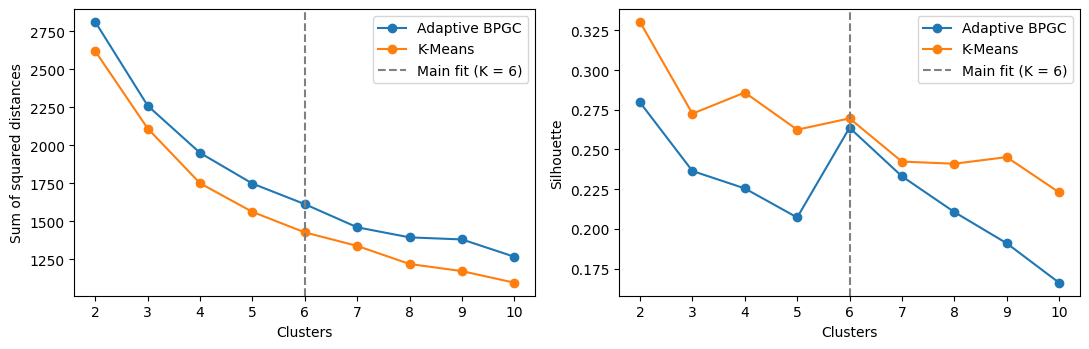

In [9]:
k_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=KMEANS_INIT, random_state=SEED).fit(X)
    fit = best_fit if k == K else fit_adaptive_bpgc(
        X, pairs, adaptive_weights, k=k, lam=best_lambda, seed=SEED,
        restarts=RESTARTS, max_iter=MAX_ITER, inner_sweeps=INNER_SWEEPS,
    )
    score = evaluate(ADAPTIVE_METHOD, X, fit["labels"], pairs, weights)
    k_rows.append({
        "K": k,
        "Adaptive_BPGC_SSE": score["SSE"],
        "Adaptive_BPGC_Silhouette": score["Silhouette"],
        "Adaptive_BPGC_Davies_Bouldin": score["Davies_Bouldin"],
        "Adaptive_BPGC_Spatial_Consistency_Adj": score["Spatial_Consistency_Adj"],
        "KMeans_Inertia": km.inertia_,
        "KMeans_Silhouette": silhouette_score(X, km.labels_),
        "KMeans_Davies_Bouldin": davies_bouldin_score(X, km.labels_),
    })
k_sweep = pd.DataFrame(k_rows)
display(k_sweep.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(k_sweep.K, k_sweep.Adaptive_BPGC_SSE, marker="o", label=ADAPTIVE_METHOD)
axes[0].plot(k_sweep.K, k_sweep.KMeans_Inertia, marker="o", label="K-Means")
axes[0].set(xlabel="Clusters", ylabel="Sum of squared distances")
axes[1].plot(k_sweep.K, k_sweep.Adaptive_BPGC_Silhouette, marker="o", label=ADAPTIVE_METHOD)
axes[1].plot(k_sweep.K, k_sweep.KMeans_Silhouette, marker="o", label="K-Means")
axes[1].set(xlabel="Clusters", ylabel="Silhouette")
for ax in axes:
    ax.axvline(K, ls="--", color="gray", label=f"Main fit (K = {K})")
    ax.legend()
fig.tight_layout()
plt.show()

## 10. Cluster interpretation and visualizations

Profiles show each cluster's mean standardized features. Representative station-windows are the observations closest to their cluster mean. The PCA projection is shared across panels; DBSCAN noise is gray.

Adaptive BPGC profiles and representative station-windows


,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16,check_in_share_16_20,check_in_share_20_24,check_out_share_00_07,check_out_share_07_10,check_out_share_10_16,check_out_share_16_20,check_out_share_20_24,net_flow_00_07,net_flow_07_10,net_flow_10_16,net_flow_16_20,net_flow_20_24,weekend_share,volume_share
cluster,,,,,,,,,,,,,,,,,
0,-1.079,-1.108,-0.723,1.597,-0.437,0.916,1.760,-0.163,-1.540,-1.329,-1.419,-1.394,-0.076,1.596,0.999,-1.046,-0.697
1,0.888,1.048,0.170,-0.832,-0.398,-0.469,-0.746,-0.635,0.855,0.842,0.838,0.991,0.476,-0.897,-0.869,0.060,0.348
2,-0.408,-0.339,0.192,0.377,-0.189,-0.008,0.297,0.174,-0.316,-0.238,-0.334,-0.463,-0.056,0.357,0.019,-0.150,-0.064
3,-0.485,-0.396,0.324,-0.284,1.021,-0.675,-0.578,1.103,0.457,-0.100,0.281,0.103,-0.776,-0.384,0.515,1.163,0.105
4,-0.822,-1.563,-2.356,0.237,3.671,-0.850,-0.236,2.045,0.255,-1.022,0.052,-1.383,-3.196,0.030,2.041,0.995,1.424
5,1.379,-0.054,0.633,-0.775,0.474,2.946,-0.429,-0.045,-0.806,0.624,-0.341,0.409,1.141,0.302,0.098,-0.044,-0.852


,cluster,station,window,prototype_distance_sq
0,0,Equiti,W18/19,0.924
1,0,Equiti,W17/18,1.006
2,0,Equiti,W19/20,1.196
3,1,Abu Baker Al Siddique,W21/22,1.176
4,1,Mashreq,W24/25,1.587
5,1,Al Nahda,W19/20,1.625
6,2,Financial Centre,W24/25,0.831
7,2,World Trade Centre,W21/22,0.943
8,2,Emirates Towers,W21/22,2.006
9,3,Al Ghubaiba,W17/18,1.515


DBSCAN profiles and representative station-windows


,check_in_share_00_07,check_in_share_07_10,check_in_share_10_16,check_in_share_16_20,check_in_share_20_24,check_out_share_00_07,check_out_share_07_10,check_out_share_10_16,check_out_share_16_20,check_out_share_20_24,net_flow_00_07,net_flow_07_10,net_flow_10_16,net_flow_16_20,net_flow_20_24,weekend_share,volume_share
cluster,,,,,,,,,,,,,,,,,
0,-0.009,0.056,-0.010,-0.012,-0.044,-0.182,0.005,-0.006,0.029,0.028,0.080,0.026,-0.065,-0.044,-0.076,-0.039,0.088
1,1.567,-0.114,0.750,-0.920,0.658,2.789,-0.519,0.121,-0.823,0.737,-0.240,0.412,0.959,0.203,0.119,0.116,-0.794
2,-1.201,-1.041,1.307,0.402,0.261,0.177,0.389,0.219,0.386,-1.330,-1.256,-0.960,0.938,0.201,1.464,0.688,0.086
3,-1.389,-1.474,-2.259,2.281,0.020,1.945,0.990,-0.788,-0.570,-1.143,-1.910,-1.469,-0.076,1.456,1.356,0.054,-1.242


,cluster,station,window,center_distance_sq
0,0,Financial Centre,W19/20,1.361
1,0,Financial Centre,W24/25,1.554
2,0,ONPASSIVE,W19/20,1.568
3,1,Airport Terminal 1,W18/19,1.034
4,1,Airport Terminal 3,W21/22,1.561
5,1,Airport Terminal 3,W19/20,2.634
6,2,Oud Metha,W18/19,0.358
7,2,Oud Metha,W19/20,0.772
8,2,Oud Metha,W21/22,0.988
9,3,Creek,W19/20,0.300


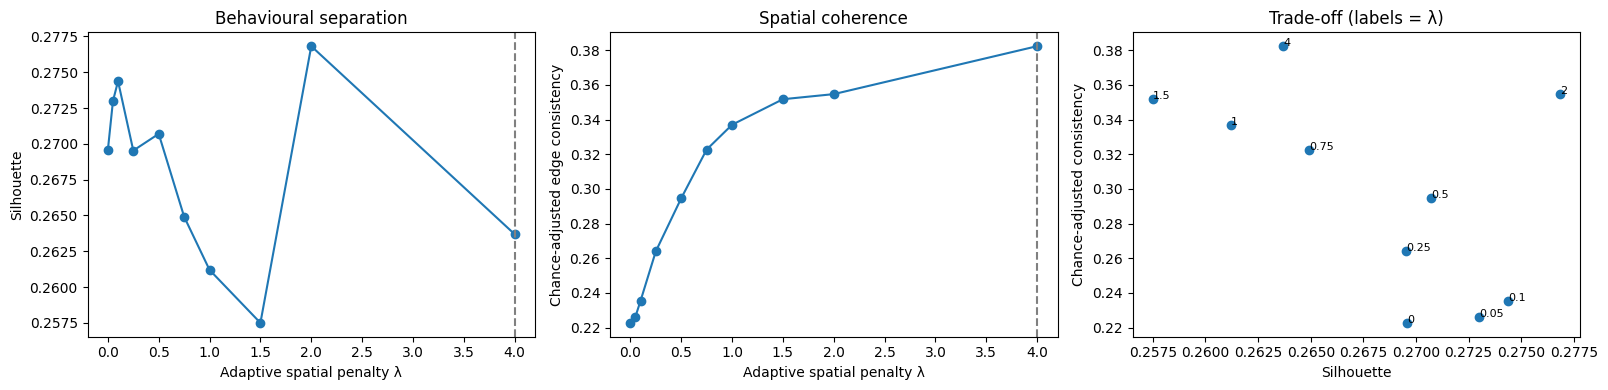

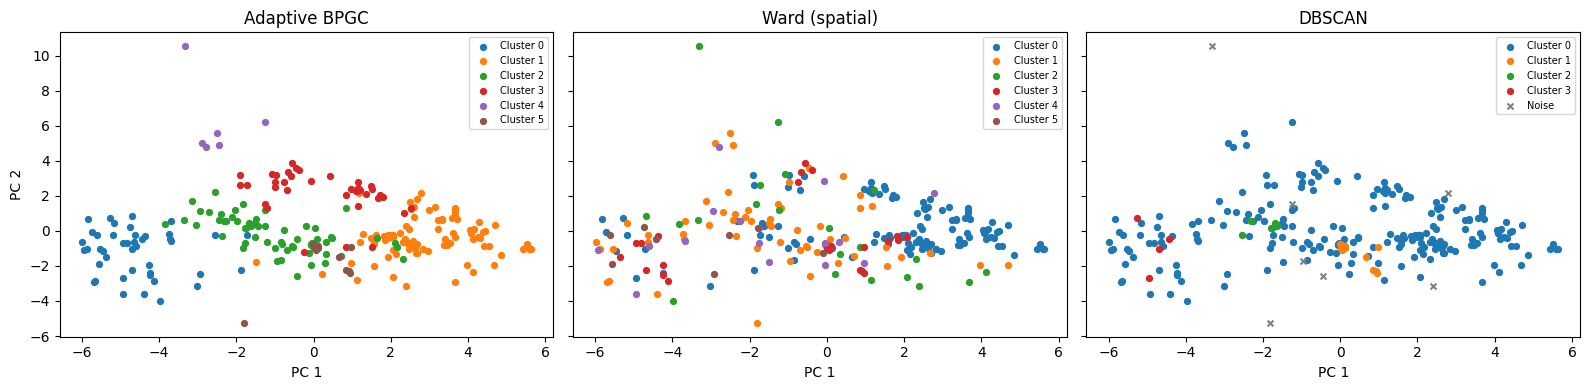

In [10]:
assignments = df[KEY_COLUMNS].copy()
assignments["cluster"] = adaptive_labels
assignments["ward_spatial_cluster"] = ward_sp_labels
assignments["dbscan_cluster"] = dbscan_labels
assignments["method"] = "adaptive_bpgc"
assignments["k"] = K
assignments["lambda"] = best_lambda
assignments["local_neighbors"] = LOCAL_NEIGHBORS

def cluster_tables(labels, distance_column):
    assigned = labels != -1
    profiles = df.loc[assigned, feature_cols].groupby(labels[assigned]).mean()
    profiles.index.name = "cluster"
    representatives = []
    for cluster, center in profiles.iterrows():
        indices = np.flatnonzero(labels == cluster)
        distances = sqdist(X[indices], center.to_numpy()[None, :]).ravel()
        for nearest in np.argsort(distances)[:3]:
            i = indices[nearest]
            representatives.append({"cluster": cluster, "station": df.loc[i, "station"],
                                    "window": df.loc[i, "win"], distance_column: distances[nearest]})
    columns = ["cluster", "station", "window", distance_column]
    return profiles, pd.DataFrame(representatives, columns=columns)

profiles, representatives = cluster_tables(adaptive_labels, "prototype_distance_sq")
dbscan_profiles, dbscan_representatives = cluster_tables(dbscan_labels, "center_distance_sq")
print(f"{ADAPTIVE_METHOD} profiles and representative station-windows")
display(profiles.round(3)); display(representatives.round(3))
print("DBSCAN profiles and representative station-windows")
display(dbscan_profiles.round(3)); display(dbscan_representatives.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(sweep["Lambda"], sweep["Silhouette"], marker="o")
axes[0].axvline(best_lambda, ls="--", c="gray")
axes[0].set(xlabel="Adaptive spatial penalty λ", ylabel="Silhouette", title="Behavioural separation")
axes[1].plot(sweep["Lambda"], sweep["Spatial_Consistency_Adj"], marker="o")
axes[1].axvline(best_lambda, ls="--", c="gray")
axes[1].set(xlabel="Adaptive spatial penalty λ", ylabel="Chance-adjusted edge consistency", title="Spatial coherence")
axes[2].scatter(sweep["Silhouette"], sweep["Spatial_Consistency_Adj"])
for _, r in sweep.iterrows():
    axes[2].annotate(f"{r.Lambda:g}", (r.Silhouette, r.Spatial_Consistency_Adj), fontsize=8)
axes[2].set(xlabel="Silhouette", ylabel="Chance-adjusted consistency", title="Trade-off (labels = λ)")
plt.tight_layout(); plt.show()

projection = PCA(n_components=2).fit_transform(X)
panels = [(ADAPTIVE_METHOD, adaptive_labels), ("Ward (spatial)", ward_sp_labels), ("DBSCAN", dbscan_labels)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (method, labels) in zip(axes, panels):
    for cluster in np.unique(labels[labels != -1]):
        pts = projection[labels == cluster]
        ax.scatter(pts[:, 0], pts[:, 1], s=18, label=f"Cluster {cluster}")
    noise = projection[labels == -1]
    if len(noise):
        ax.scatter(noise[:, 0], noise[:, 1], s=18, color="gray", marker="x", label="Noise")
    ax.set(xlabel="PC 1", title=method); ax.legend(fontsize=7)
axes[0].set_ylabel("PC 2")
fig.tight_layout(); plt.show()

## 11. Save outputs and print final results

In [11]:
comparison.to_csv(OUTPUT_DIR/"bpgc_model_comparison.csv", index=False)
sweep.to_csv(OUTPUT_DIR/"bpgc_lambda_sweep.csv", index=False)
ncut.to_csv(OUTPUT_DIR/"bpgc_normalized_cut.csv", index=False)
stability.to_csv(OUTPUT_DIR/"bpgc_stability_summary.csv", index=False)
stability_repeats.to_csv(OUTPUT_DIR/"bpgc_stability_repeats.csv", index=False)
paired.to_csv(OUTPUT_DIR/"bpgc_stability_paired.csv", index=False)
k_sweep.to_csv(OUTPUT_DIR/"bpgc_k_sweep.csv", index=False)
assignments.to_csv(OUTPUT_DIR/"bpgc_labels.csv", index=False)
profiles.to_csv(OUTPUT_DIR/"bpgc_cluster_profiles.csv")
representatives.to_csv(OUTPUT_DIR/"bpgc_representative_stations.csv", index=False)
dbscan_profiles.to_csv(OUTPUT_DIR/"dbscan_cluster_profiles.csv")
dbscan_representatives.to_csv(OUTPUT_DIR/"dbscan_representative_stations.csv", index=False)
print(f"{ADAPTIVE_METHOD} and baseline results")
display(comparison.round(4))
print("NORMALIZED CUT"); display(ncut.round(4))
print("STABILITY"); display(stability.round(4))
print("PAIRED STABILITY vs K-Means"); display(paired.round(4))
print("Selected λ:", best_lambda, "| clusters:", K, "| local neighbour rank:", LOCAL_NEIGHBORS)
print("Files saved to:", OUTPUT_DIR)
print("DBSCAN largest-cluster share:", round(comparison.loc[dbscan_row, "Largest_Cluster_Share"].iloc[0], 3))

Adaptive BPGC and baseline results


,Method,N,Clusters,Noise_Points,Coverage,Silhouette,Davies_Bouldin,Calinski_Harabasz,SSE,Spatial_Consistency,Spatial_Consistency_Adj,Spatial_Edge_Coverage,Smallest_Cluster,Largest_Cluster,Largest_Cluster_Share,Eps,Min_Samples,Lambda,Local_Neighbors
0,K-Means,244,6,0,1.0000,0.2696,1.3129,90.8593,1426.0136,0.3893,0.2227,1.0000,6,72,0.2951,NaN,NaN,NaN,NaN
1,Ward,244,6,0,1.0000,0.2785,1.3151,81.7876,1525.9942,0.4795,0.3179,1.0000,6,83,0.3402,NaN,NaN,NaN,NaN
2,Ward (spatial),244,6,0,1.0000,0.0314,4.9856,10.5276,3396.7504,0.9549,0.9334,1.0000,8,116,0.4754,NaN,NaN,NaN,NaN
3,Adaptive BPGC (λ=4),244,6,0,1.0000,0.2637,1.3236,74.8858,1611.9809,0.5410,0.3823,1.0000,6,88,0.3607,NaN,NaN,4.0,7.0
4,DBSCAN,244,4,7,0.9713,-0.0124,1.2063,8.1086,3477.5383,0.8957,0.2543,0.9426,4,218,0.9198,2.6423,5.0,NaN,NaN


NORMALIZED CUT


,Method,Partitions,Noise_Points,Ncut (same graph),Ncut_ratio
0,K-Means,6,0,4.6204,0.9241
1,Ward,6,0,4.6315,0.9263
2,Ward (spatial),6,0,4.8347,0.9669
3,Adaptive BPGC (λ=4),6,0,4.6376,0.9275
4,DBSCAN,5,7,3.9515,0.9879


STABILITY


,Method,mean,std,min,max
0,Adaptive BPGC,0.6685,0.0520,0.6004,0.7726
1,DBSCAN,0.9352,0.0838,0.6881,1.0000
2,K-Means,0.8803,0.0988,0.6523,0.9851
3,Ward,0.7522,0.1259,0.5108,0.9749
4,Ward (spatial),0.2001,0.0995,0.0751,0.3846


PAIRED STABILITY vs K-Means


,Method,Mean_diff_vs_KMeans,SE,Diff_over_SE
0,Adaptive BPGC,-0.2118,0.0222,-9.5240
1,DBSCAN,0.0549,0.0294,1.8663
2,Ward,-0.1281,0.0390,-3.2820
3,Ward (spatial),-0.6802,0.0319,-21.3031


Selected λ: 4.0 | clusters: 6 | local neighbour rank: 7
Files saved to: /Users/aryanchandra/Downloads/Metro-Spectral-STGRSC/results/bpgc
DBSCAN largest-cluster share: 0.92
